# Ящик з вусами: квантильний метод vs метод mean ± 1.96·std

Порівняння двох способів побудови box plot для вибірок з **N(0, 1)** та **Cauchy(0, 1)**:
1. класичний (Тьюкі) — на основі квантилів;
2. на основі вибіркового середнього та стандартного відхилення: `mean ± 1.96·std`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
n = 1000  # розмір вибірки

In [2]:
# Вибірки
normal_sample = np.random.normal(loc=0, scale=1, size=n)   # N(0, 1)
cauchy_sample = np.random.standard_cauchy(size=n)           # Cauchy(0, 1), тобто t-розподіл Стьюдента з 1 степенем волі

## Два методи побудови ящика

| Метод | Межі ящика | Вуса | Викиди |
|---|---|---|---|
| Квантильний (Тьюкі) | Q1 ... Q3 (25-й і 75-й перцентилі) | найдальша точка в межах 1.5·IQR від краю ящика | точки за межами 1.5·IQR — показуються окремо |
| `mean ± 1.96·std` | mean − std ... mean + std | mean − 1.96·std ... mean + 1.96·std | не визначені — метод припускає нормальність |

Квантильний метод — непараметричний і робастний до форми розподілу.
Метод `mean ± 1.96·std` коректний лише тоді, коли вибіркові mean і std є скінченними й стабільними оцінками параметрів розподілу (як у нормального).

In [3]:
def quantile_box_stats(data):
    """
    Класичний ящик з вусами (правило Тьюкі):
    - межі ящика: Q1 (25-й перцентиль), Q3 (75-й перцентиль)
    - вуса тягнуться до найдальшого спостереження в межах 1.5*IQR від краю ящика
    - усе, що лишилось поза цими межами, -> викиди (fliers), показуються окремими точками
    """
    q1, median, q3 = np.percentile(data, [25, 50, 75])
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    inside = data[(data >= lower_fence) & (data <= upper_fence)]
    fliers = data[(data < lower_fence) | (data > upper_fence)]

    return {
        "med": median, "q1": q1, "q3": q3,
        "whislo": inside.min(), "whishi": inside.max(),
        "fliers": fliers,
    }

In [4]:
def mean_std_box_stats(data):
    """
    Ящик на основі mean +/- 1.96*std:
    - "медіана" ящика замінена на вибіркове середнє
    - межі ящика: mean +/- std
    - вуса: mean +/- 1.96*std (95% інтервал за нормальним наближенням)
    - метод не виявляє викидів окремо -- усе, що не влізло, просто розтягує вуса
    """
    mean = np.mean(data)
    std = np.std(data, ddof=1)

    return {
        "med": mean, "q1": mean - std, "q3": mean + std,
        "whislo": mean - 1.96 * std, "whishi": mean + 1.96 * std,
        "fliers": np.array([]),
    }

In [5]:
stats_normal_q = quantile_box_stats(normal_sample)
stats_normal_m = mean_std_box_stats(normal_sample)
stats_cauchy_q = quantile_box_stats(cauchy_sample)
stats_cauchy_m = mean_std_box_stats(cauchy_sample)

# Таблиця з характеристиками обох ящиків для обох вибірок
summary = pd.DataFrame({
    "Normal, квантилі":      stats_normal_q,
    "Normal, mean±1.96std":  stats_normal_m,
    "Cauchy, квантилі":      stats_cauchy_q,
    "Cauchy, mean±1.96std":  stats_cauchy_m,
}).T[["q1", "med", "q3", "whislo", "whishi"]]

summary

,q1,med,q3,whislo,whishi
"Normal, квантилі",-0.64759,0.025301,0.647944,-2.471645,2.57336
"Normal, mean±1.96std",-0.959884,0.019332,0.998548,-1.899931,1.938595
"Cauchy, квантилі",-1.017805,0.032108,0.925823,-3.89041,3.748357
"Cauchy, mean±1.96std",-35.027258,0.871336,36.769929,-69.489907,71.232578


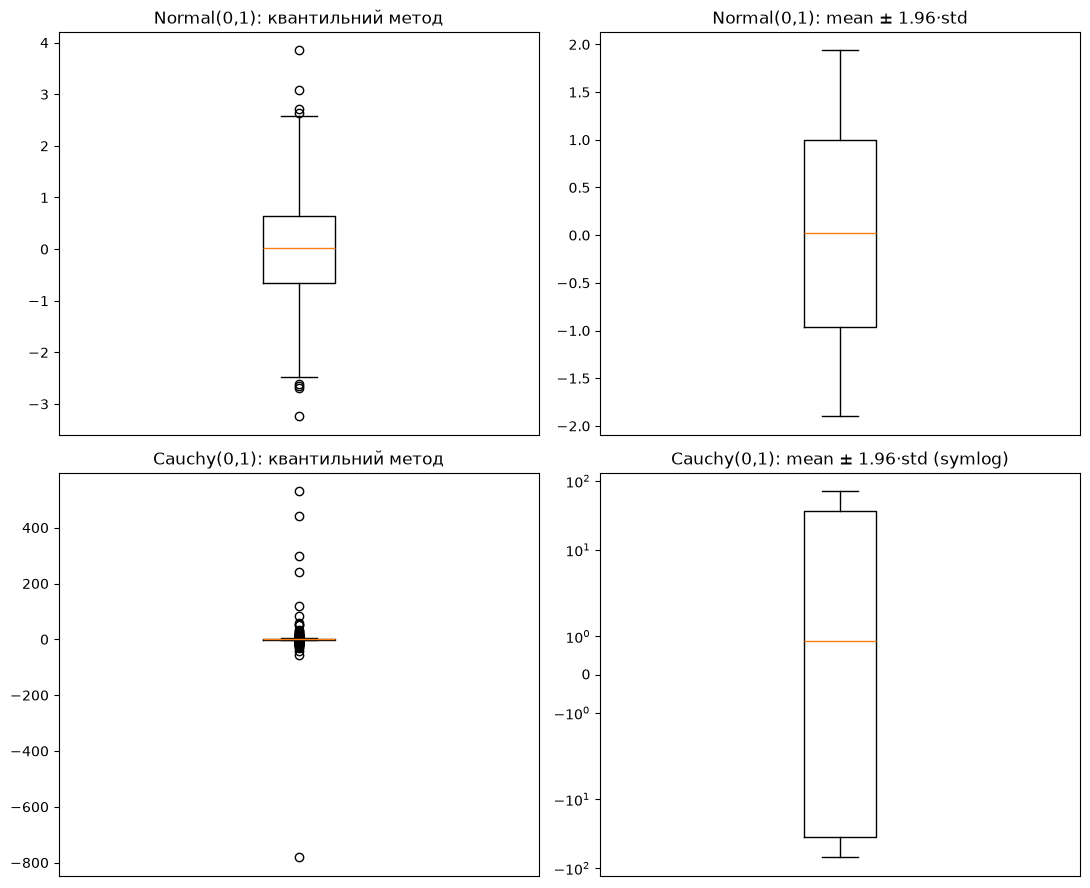

Cauchy, квантильний метод: 134 викидів із 1000
Cauchy, mean±1.96std вуса: [-69.5, 71.2]


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

axes[0, 0].bxp([stats_normal_q], showfliers=True)
axes[0, 0].set_title("Normal(0,1): квантильний метод")

axes[0, 1].bxp([stats_normal_m], showfliers=False)
axes[0, 1].set_title("Normal(0,1): mean ± 1.96·std")

axes[1, 0].bxp([stats_cauchy_q], showfliers=True)
axes[1, 0].set_title("Cauchy(0,1): квантильний метод")

axes[1, 1].bxp([stats_cauchy_m], showfliers=False)
axes[1, 1].set_yscale("symlog")  # без цього вуса (десь ±70) роблять ящик невидимим
axes[1, 1].set_title("Cauchy(0,1): mean ± 1.96·std (symlog)")

for ax in axes.flat:
    ax.set_xticks([])

plt.tight_layout()
plt.show()

n_fliers = len(stats_cauchy_q["fliers"])
print(f"Cauchy, квантильний метод: {n_fliers} викидів із {n}")
print(f"Cauchy, mean±1.96std вуса: [{stats_cauchy_m['whislo']:.1f}, {stats_cauchy_m['whishi']:.1f}]")

**Normal(0, 1)** — обидва методи дають подібний результат: розподіл симетричний, mean і std добре визначені й стабільні.

**Cauchy(0, 1)** — метод `mean ± 1.96·std` ламається:
- у розподілу Коші не існує скінченного математичного сподівання і дисперсії;
- вибіркові mean і std не збігаються до сталих значень зі збільшенням n — вони залежать від конкретних (рідких, але дуже великих за модулем) спостережень у вибірці;
- через це межі ящика й вуса можуть відрізнятись у десятки-сотні разів між різними вибірками того самого розміру.

Квантильний метод стабільний в обох випадках, бо базується на порядкових статистиках (перцентилях), існування яких не залежить від існування моментів розподілу.

## Cтабільність методів між повторними вибірками

Одного прогону недостатньо, щоб побачити нестабільність — покажемо це, повторивши експеримент K разів.

In [7]:
# Повторюємо вибірку K разів
K = 200

def iqr_width(data):
    q1, q3 = np.percentile(data, [25, 75])
    return q3 - q1

def meanstd_width(data):
    return 2 * 1.96 * np.std(data, ddof=1)

widths = {"norm_quantile": [], "norm_meanstd": [], "cauchy_quantile": [], "cauchy_meanstd": []}
for _ in range(K):
    ns = np.random.normal(0, 1, n)
    cs = np.random.standard_cauchy(n)
    widths["norm_quantile"].append(iqr_width(ns))
    widths["norm_meanstd"].append(meanstd_width(ns))
    widths["cauchy_quantile"].append(iqr_width(cs))
    widths["cauchy_meanstd"].append(meanstd_width(cs))

# mean_width, std_width, max_width -- статистики ширини ящика по K повторним вибіркам
stability = pd.DataFrame({
    k: {"mean_width": np.mean(v), "std_width": np.std(v), "max_width": np.max(v)}
    for k, v in widths.items()
}).T

stability

,mean_width,std_width,max_width
norm_quantile,1.352962,0.055688,1.500231
norm_meanstd,3.925314,0.088017,4.151205
cauchy_quantile,1.997288,0.093510,2.270893
cauchy_meanstd,1284.199360,10706.807861,148287.553390


`std_width` — це стандартне відхилення *ширини ящика* між K=200 незалежними вибірками, тобто наскільки метод чутливий до конкретної вибірки, а не до самого розподілу.

- **Normal**: обидва методи дають стабільну ширину (`std_width` малий відносно `mean_width`).
- **Cauchy, квантилі**: ширина лишається стабільною — приблизно як у нормального.
- **Cauchy, mean±1.96·std**: `std_width` у сотні разів більший за `mean_width`, а `max_width` може вистрибувати на тисячі одиниць — це пряме наслідок відсутності скінченної дисперсії в розподілу Коші.